# Notebook 03 — Models vs the rules

**Project:** deepbook-flowcast — predicting short-term price moves on DeepBook, Sui's on-chain order book.

**Question:** do machine-learning models beat the simple rules at predicting where the mid-price goes next
(`UP`, `FLAT`, `DOWN`), and is the edge big enough to matter?

**What was trained (with `flowcast train logreg` / `flowcast train lgbm`):**
- **Logistic regression** — one weighted sum per class, after `log1p`, clipping and scaling (decisions from notebook 01).
- **LightGBM** — hundreds of small decision trees; can learn thresholds and interactions.
- Both tuned with `TimeSeriesSplit(3)` **inside August**, refit on all of August, scored on **September**.
  October and 2026 stay untouched.

**The rules to beat** (tuned on August): always-flat, the order-book imbalance rule, the Binance lead-lag rule.

**Metric:** macro F1 (0–1, the average of the F1 for UP, FLAT and DOWN), so always saying FLAT can't look good.

This notebook loads the saved models; it does not retrain anything. Most cells look at **SUI_USDC, 10 seconds ahead**,
the same setting as notebook 01.

## 1. Imports

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from flowcast.config import RUNS
from flowcast.labels import load_labels
from flowcast.models.data import VALID, load_table, xy
from flowcast.models.pipeline import coefficients, importances, shap_values
from flowcast.models.train import load_model

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

## 2. Results of every run

Each training run saved its scores in `runs/<time>_<model>/results.csv`. We stack the logistic regression
and LightGBM runs and line them up against the best rule for each pool and horizon.

- `sep_f1` = macro F1 on September (the score that counts here)
- `features`: `deepbook` = DeepBook data only, `all` = DeepBook + Binance
- `trained_on`: for DEEP_USDC there is also a row where the **SUI_USDC** model is used as-is ("does it carry over?")

In [2]:
# Load the results of the two runs
RUN_LOGREG, RUN_LGBM = "20261009-182404_logreg", "20261009-191600_lgbm"
res = pd.concat([pd.read_csv(RUNS / r / "results.csv") for r in (RUN_LOGREG, RUN_LGBM)], ignore_index=True)

own = res[res.trained_on == res.pool]                        # each pool's own model
table = own.pivot_table(index=["pool", "horizon"], columns=["model", "features"], values="sep_f1")
table.insert(0, "best_rule", own.groupby(["pool", "horizon"]).best_rule_f1.first())
table = table.reindex(["1s", "10s", "60s"], level="horizon").round(3)
table

model             best_rule   lgbm          logreg         
features                       all deepbook    all deepbook
pool      horizon                                          
DEEP_USDC 1s          0.424  0.502    0.482  0.403    0.385
          10s         0.396  0.486    0.463  0.448    0.416
          60s         0.393  0.463    0.445  0.445    0.416
SUI_USDC  1s          0.361  0.479    0.465  0.452    0.439
          10s         0.357  0.463    0.458  0.449    0.442
          60s         0.359  0.404    0.398  0.401    0.396

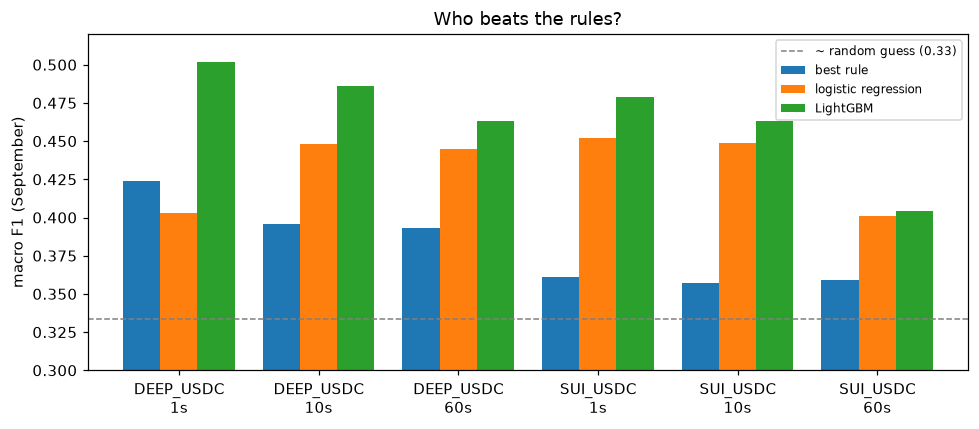

In [3]:
# Bar chart: best rule vs logistic regression vs LightGBM (DeepBook + Binance features)
plot = table[[("best_rule", ""), ("logreg", "all"), ("lgbm", "all")]]
plot.columns = ["best rule", "logistic regression", "LightGBM"]
ax = plot.plot.bar(figsize=(9, 4), width=0.8)
ax.axhline(1 / 3, color="grey", ls="--", lw=1, label="~ random guess (0.33)")
ax.set_ylabel("macro F1 (September)"); ax.set_ylim(0.3, 0.52); ax.set_xlabel("")
ax.set_xticklabels([f"{p}\n{h}" for p, h in plot.index], rotation=0)
ax.legend(loc="upper right", fontsize=8); ax.set_title("Who beats the rules?")
plt.tight_layout(); plt.show()

In [4]:
# Lift: how much each model adds over the best rule, and how much Binance adds
lift = pd.DataFrame({
    "logreg - rule": table[("logreg", "all")] - table[("best_rule", "")],
    "lgbm - rule": table[("lgbm", "all")] - table[("best_rule", "")],
    "lgbm - logreg": table[("lgbm", "all")] - table[("logreg", "all")],
    "Binance adds (lgbm)": table[("lgbm", "all")] - table[("lgbm", "deepbook")],
}).round(3)
lift

logreg - rule  lgbm - rule  lgbm - logreg  \
pool      horizon                                              
DEEP_USDC 1s              -0.021        0.078          0.099   
          10s              0.052        0.090          0.038   
          60s              0.052        0.070          0.018   
SUI_USDC  1s               0.091        0.118          0.027   
          10s              0.092        0.106          0.014   
          60s              0.042        0.045          0.003   

                   Binance adds (lgbm)  
pool      horizon                       
DEEP_USDC 1s                     0.020  
          10s                    0.023  
          60s                    0.018  
SUI_USDC  1s                     0.014  
          10s                    0.005  
          60s                    0.006

In [5]:
# Carry-over: SUI_USDC models scored on DEEP_USDC as-is, vs DEEP's own model and DEEP's best rule
carry = res[(res.pool == "DEEP_USDC") & (res.features == "all")]
carry.pivot_table(index="horizon", columns=["model", "trained_on"], values="sep_f1").reindex(["1s", "10s", "60s"]).assign(
    best_rule=carry.groupby("horizon").best_rule_f1.first()).round(3)

model           lgbm             logreg          best_rule
trained_on DEEP_USDC SUI_USDC DEEP_USDC SUI_USDC          
horizon                                                   
1s             0.502    0.263     0.403    0.235     0.424
10s            0.486    0.443     0.448    0.426     0.396
60s            0.463    0.422     0.445    0.393     0.393

## 3. Load September for SUI_USDC, 10 seconds ahead

As in notebook 01 we keep **one row every 10 seconds**: neighbouring seconds are near-duplicates,
and predicting 2.6 million rows with LightGBM is slow. The picture is the same.

`ret_10s` (the actual move over the next 10 s, in basis points) comes from the labels files; it is **not** a
model input, only used to measure what the predictions were worth.

In [6]:
# September features + labels, every 10th second
va = load_table("SUI_USDC", *VALID)
Xv, yv = xy(va, "10s", "all")
X, y = Xv.iloc[::10], yv.iloc[::10]

# The actual 10-second move (bps), lined up with X by timestamp
ret = load_labels("SUI_USDC", *VALID).set_index("ts").loc[va.loc[X.index, "ts"], "ret_10s"].to_numpy()

logreg = load_model("logreg", "SUI_USDC", "10s", "all", run=RUN_LOGREG)
lgbm = load_model("lgbm", "SUI_USDC", "10s", "all", run=RUN_LGBM)
pred = {"logistic regression": logreg.predict(X), "LightGBM": lgbm.predict(X)}
print(f"{len(X):,} September rows, {X.shape[1]} features;  class shares:",
      y.map({-1: "DOWN", 0: "FLAT", 1: "UP"}).value_counts(normalize=True).round(3).to_dict())

259,200 September rows, 33 features;  class shares: {'FLAT': 0.491, 'UP': 0.255, 'DOWN': 0.254}


## 4. Confusion matrices

Each row is the **true** class and sums to 1 (`normalize="true"`), so the diagonal is the share of each class
the model catches. The interesting cells are UP ↔ DOWN: calling a move in the **wrong direction** is worse than
calling FLAT.

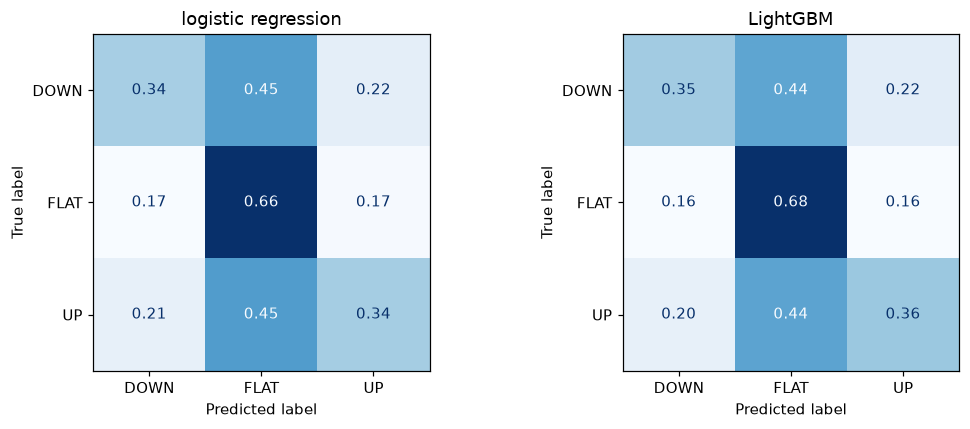

In [7]:
# Confusion matrices, side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, p) in zip(axes, pred.items()):
    ConfusionMatrixDisplay.from_predictions(y, p, labels=[-1, 0, 1], display_labels=["DOWN", "FLAT", "UP"],
                                            normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [8]:
# Precision, recall and F1 per class
for name, p in pred.items():
    print(name); print(classification_report(y, p, labels=[-1, 0, 1], target_names=["DOWN", "FLAT", "UP"], digits=3))

logistic regression
              precision    recall  f1-score   support

        DOWN      0.386     0.337     0.360     65805
        FLAT      0.586     0.657     0.620    127363
          UP      0.384     0.343     0.362     66032

    accuracy                          0.496    259200
   macro avg      0.452     0.446     0.447    259200
weighted avg      0.484     0.496     0.488    259200

LightGBM
              precision    recall  f1-score   support

        DOWN      0.403     0.347     0.373     65805
        FLAT      0.598     0.676     0.634    127363
          UP      0.403     0.357     0.379     66032

    accuracy                          0.511    259200
   macro avg      0.468     0.460     0.462    259200
weighted avg      0.499     0.511     0.503    259200



## 5. What each model relies on

- **Logistic regression:** its weights. `up − down` > 0 means a higher value of the (scaled) feature pushes toward UP.
- **LightGBM:** `gain` = how much each feature reduced the training loss across all its splits.
  It says how much a feature is used, not in which direction.

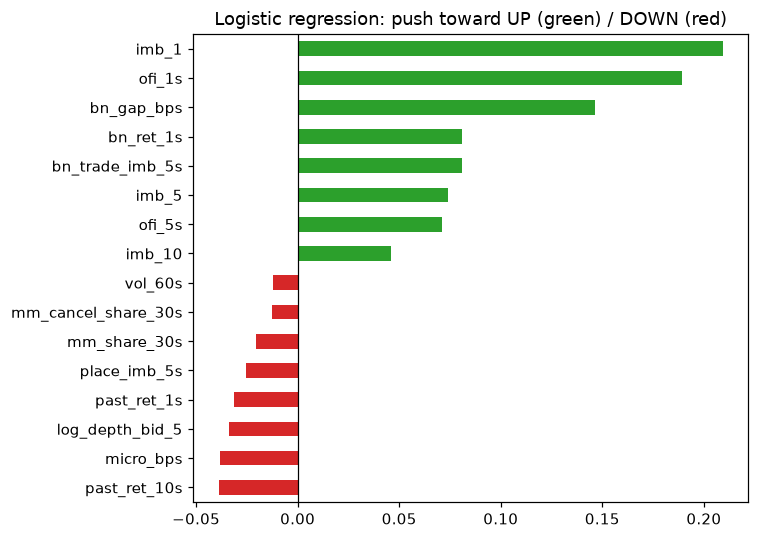

In [9]:
# Logistic regression: the 8 strongest pushes toward UP and toward DOWN
c = coefficients(logreg)
c["up - down"] = c["up"] - c["down"]
c = c.sort_values("up - down")
pd.concat([c.head(8), c.tail(8)])["up - down"].plot.barh(figsize=(7, 5), color=["tab:red"] * 8 + ["tab:green"] * 8)
plt.title("Logistic regression: push toward UP (green) / DOWN (red)"); plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

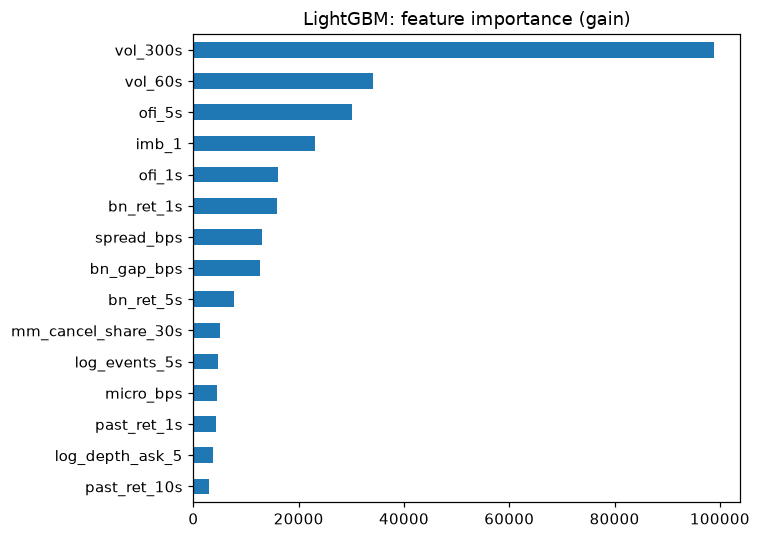

In [10]:
# LightGBM: top 15 features by gain
importances(lgbm).head(15).sort_values().plot.barh(figsize=(7, 5))
plt.title("LightGBM: feature importance (gain)"); plt.tight_layout(); plt.show()

## 6. SHAP: why LightGBM predicts what it predicts

SHAP splits each prediction into one contribution per feature (in log-odds): positive = that feature pushed this
prediction toward the class. The contributions plus a `bias` add up exactly to the model's score.
We use a sample of 20,000 rows (plenty, and fast).

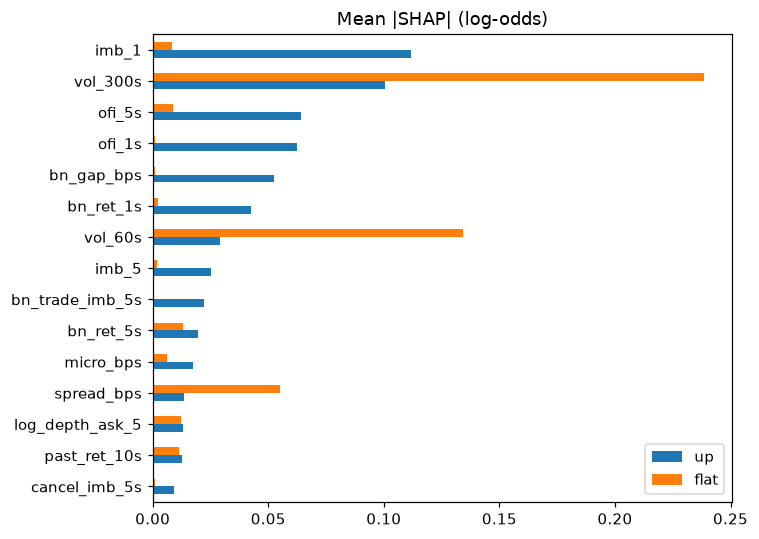

In [11]:
# SHAP values for a 20,000-row sample
Xs = X.sample(20_000, random_state=0)
sv = shap_values(lgbm, Xs)                     # {"down": ..., "flat": ..., "up": ...}

# Average absolute push per feature, for UP and for FLAT
mean_abs = pd.DataFrame({k: sv[k].drop(columns="bias").abs().mean() for k in ("up", "flat")})
mean_abs.sort_values("up").tail(15).plot.barh(figsize=(7, 5))
plt.title("Mean |SHAP| (log-odds)"); plt.tight_layout(); plt.show()

**Dependence plots:** each dot is one row; x = the feature's value, y = how much it pushed toward UP.
A straight diagonal line means a linear effect (which logistic regression can also learn); a flat stretch that
then bends means a **threshold**, which only the trees can learn.

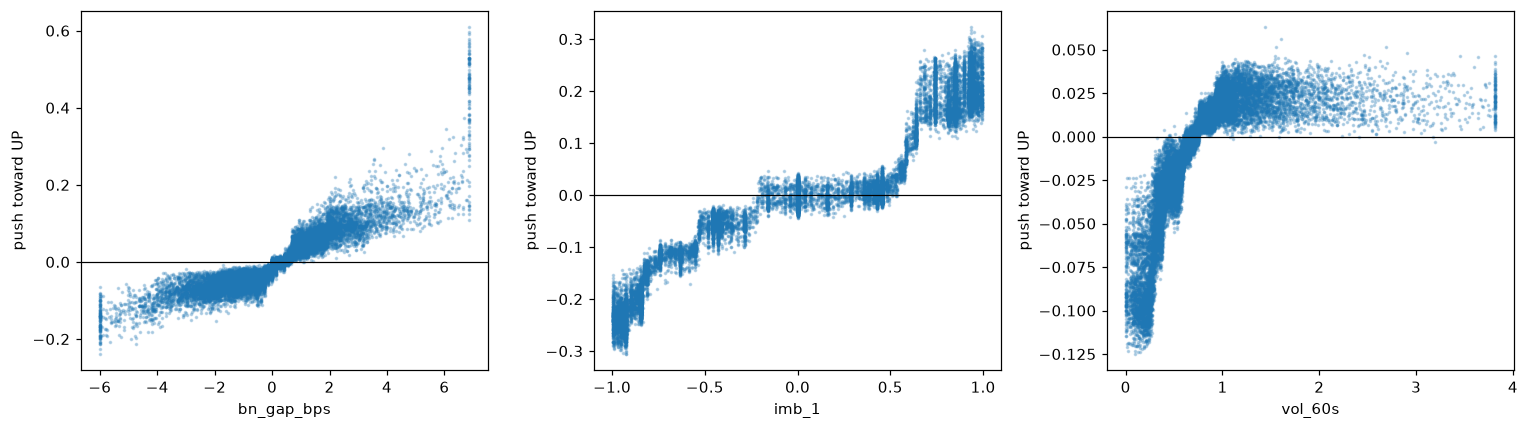

In [12]:
# Dependence plots for one direction feature, one book feature and one activity feature
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, f in zip(axes, ["bn_gap_bps", "imb_1", "vol_60s"]):
    x = Xs[f].clip(Xs[f].quantile(0.005), Xs[f].quantile(0.995))
    ax.scatter(x, sv["up"][f], s=2, alpha=0.25)
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(f); ax.set_ylabel("push toward UP")
plt.tight_layout(); plt.show()

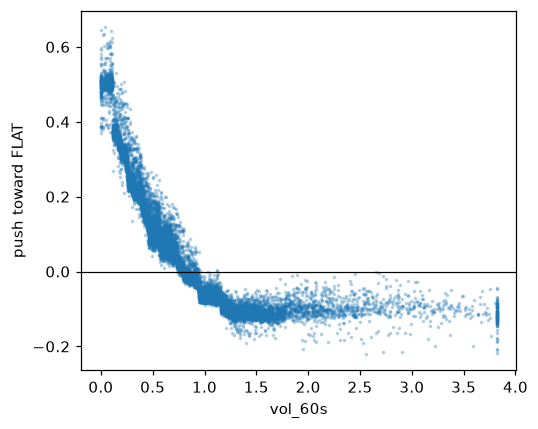

In [13]:
# vol_60s pushes toward "a move" (away from FLAT), not toward a direction
plt.figure(figsize=(5, 4))
x = Xs["vol_60s"].clip(upper=Xs["vol_60s"].quantile(0.995))
plt.scatter(x, sv["flat"]["vol_60s"], s=2, alpha=0.25)
plt.axhline(0, color="k", lw=0.8); plt.xlabel("vol_60s"); plt.ylabel("push toward FLAT")
plt.tight_layout(); plt.show()

## 7. Directional accuracy and the money question

Accuracy over three classes (up/flat/down) is not the number a trader cares about. For every UP or DOWN call:
- did the price **go that way**, **go against** it, or **not move**?
- how far did it move **in the predicted direction**, on average (bps)?

Compare that move with the cost of acting on it as a **taker**: buying at the ask and selling at the bid costs about one
**spread** per round trip, plus the taker fee on both legs (measured from our trades: **~1 bp per side** when paid in
DEEP; makers pay 0).

**Use the average cost, not the median.** Profit adds up trade by trade, so expected profit = average move − average
cost. The spread has a long right tail (a few very wide moments), so the median spread understates what you pay on
average. The median is shown only as "the typical spread".


In [14]:
# What happened after each UP / DOWN call
FEE_BPS = 1.0                                                   # taker fee per side, measured from trades
rows = []
for name, p in pred.items():
    for side, s in (("UP", 1), ("DOWN", -1)):
        m = p == s
        g = s * ret[m]                                         # move in the predicted direction, bps
        cost = X.spread_bps.to_numpy()[m] + 2 * FEE_BPS        # round trip as a taker
        rows.append({"model": name, "call": side, "calls": m.sum(), "went its way": np.mean(g > 0),
                     "against": np.mean(g < 0), "directional accuracy": np.mean(g > 0) / np.mean(g != 0),
                     "avg move its way (bps)": g.mean(), "median spread": np.median(X.spread_bps[m]),
                     "avg cost (bps)": cost.mean(), "avg net (bps)": (g - cost).mean()})
pd.DataFrame(rows).round(3)

,model,call,calls,went its way,against,directional accuracy,avg move its way (bps),median spread,avg cost (bps),avg net (bps)
0,logistic regression,UP,58935,0.519,0.379,0.578,0.699,1.420,4.014,-3.315
1,logistic regression,DOWN,57423,0.516,0.377,0.578,0.737,1.348,3.838,-3.101
2,LightGBM,UP,58490,0.534,0.378,0.586,0.764,1.199,4.035,-3.271
3,LightGBM,DOWN,56788,0.536,0.373,0.590,0.815,1.177,3.750,-2.935


## 8. Confidence filtering: does the edge grow on the strongest signals?

LightGBM gives probabilities. `lean = P(UP) − P(DOWN)`: far from 0 = a confident directional call.
We keep only the top x% of rows by `|lean|`, trade in the direction of `lean`, and measure accuracy, the average
move, the **average** cost (spread + 2 × fee) and the average net. If the net turns positive on the most confident
calls, there is something to trade.


In [15]:
# Accuracy, move, cost and net for the most confident calls
proba = lgbm.predict_proba(X)                                  # columns in the order of lgbm.classes_ = [-1, 0, 1]
lean = proba[:, 2] - proba[:, 0]
spread = X.spread_bps.to_numpy()
rows = []
for q in (1.0, 0.5, 0.2, 0.1, 0.05, 0.01):
    m = np.abs(lean) >= np.quantile(np.abs(lean), 1 - q)
    g = np.sign(lean[m]) * ret[m]
    cost = spread[m] + 2 * FEE_BPS
    rows.append({"top share": f"{q:.0%}", "calls": m.sum(), "directional accuracy": np.mean(g > 0) / np.mean(g != 0),
                 "avg move its way (bps)": g.mean(), "median spread": np.median(spread[m]),
                 "avg cost (bps)": cost.mean(), "avg net (bps)": (g - cost).mean()})
conf = pd.DataFrame(rows).round(3)
conf

,top share,calls,directional accuracy,avg move its way (bps),median spread,avg cost (bps),avg net (bps)
0,100%,259200,0.577,0.539,0.894,3.400,-2.861
1,50%,129600,0.618,0.881,0.867,3.507,-2.626
2,20%,51840,0.657,1.270,0.959,3.800,-2.530
3,10%,25920,0.680,1.549,1.106,4.218,-2.669
4,5%,12960,0.701,1.898,1.146,4.909,-3.011
5,1%,2592,0.757,3.628,1.474,9.272,-5.645


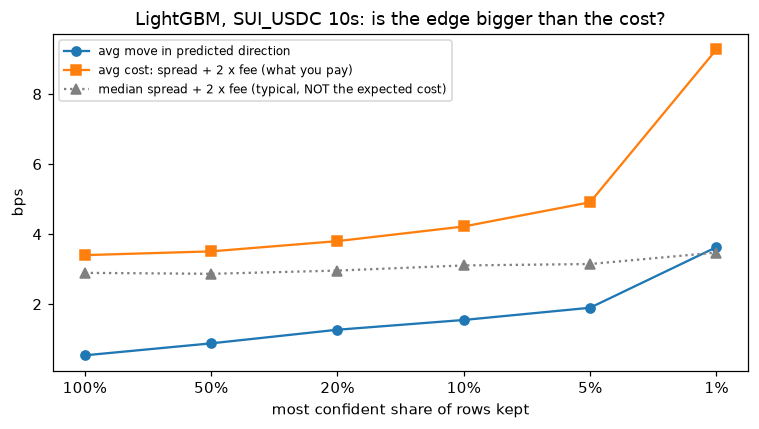

In [16]:
# The same as a chart: average move vs average cost as we keep fewer, more confident calls
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(conf["top share"], conf["avg move its way (bps)"], marker="o", label="avg move in predicted direction")
ax.plot(conf["top share"], conf["avg cost (bps)"], marker="s", label="avg cost: spread + 2 x fee (what you pay)")
ax.plot(conf["top share"], conf["median spread"] + 2 * FEE_BPS, marker="^", ls=":", color="grey",
        label="median spread + 2 x fee (typical, NOT the expected cost)")
ax.set_xlabel("most confident share of rows kept"); ax.set_ylabel("bps"); ax.legend(fontsize=8)
ax.set_title("LightGBM, SUI_USDC 10s: is the edge bigger than the cost?")
plt.tight_layout(); plt.show()

## 9. Summary and decisions

All numbers are **September 2025** (validation), point estimates; day-level bootstrap intervals for every score and lift are in `runs/20261009-232053_eval/` (`flowcast evaluate`): every lift in this table is real (interval excludes 0) except logistic regression on DEEP 1s, which is reliably worse than the rule.

| Finding | Evidence | Decision |
|---|---|---|
| **ML beats the rules everywhere on SUI_USDC** | LightGBM 0.479 / 0.463 / 0.404 vs best rule 0.361 / 0.357 / 0.359 at 1s / 10s / 60s | Keep the model ladder; rules stay as the reference rows |
| **LightGBM > logistic regression, most at short horizons** | +0.027 (1s), +0.014 (10s), +0.003 (60s) on SUI | At 60s the signal is basically linear; at 1–10s trees add real value |
| **Trees learn thresholds** | SHAP: `imb_1` is a staircase (flat until ~+0.55, then a jump); `vol_60s` saturates near 1 | This is why LightGBM fixes DEEP 1s (0.502 vs rule 0.424) where logistic regression lost (0.403) |
| **Binance helps, but DeepBook's own flow carries most of the signal** | Binance adds +0.005 to +0.014 on SUI, +0.018 to +0.023 on the thin DEEP pool | Research question 2: DeepBook is not just trailing Binance; the thin pool leans on it more |
| **Carry-over SUI → DEEP works at 10s, fails at 1s** | SUI model on DEEP: 0.443 at 10s (beats DEEP's rule), 0.263 at 1s (below always-flat) | DEEP's second-by-second regime is different; train per pool for short horizons |
| **Three-class accuracy looks low but directional accuracy is ~59%** | LightGBM 10s: accuracy 51.1%; on UP/DOWN calls where the price moved, right 58.6–59.0% | Report directional accuracy next to macro F1 |
| **On average a call doesn't pay for itself** | Avg move in the predicted direction ~0.8 bps vs average round-trip cost = spread + 2 × taker fee (~1 bp each, paid in DEEP) ≈ 3.4 bps | As a taker, trading every call loses money |
| **Confident calls are more accurate but happen when spreads are wide** | Top 1%: 76% directional accuracy and a 3.5 bps move, but the **average** cost is ~8.8 bps (median spread looks cheap at ~1.5, but a few very wide spreads coincide with these calls) | **No confidence level is profitable as a taker** (best case anywhere: SUI 60s top 1%, −2.0 bps [−3.7, −0.7] in `flowcast evaluate`). Confident "moves" are partly the mid snapping back as a wide spread closes, which a **maker** earns and a taker pays: test the maker angle instead |

**Correction (Oct 9):** an earlier version compared the confident calls' move with the *median* spread and called the top 1% "roughly break-even"; expected profit needs the *average* cost, which is ~2.5x higher there.

**Caveats:** the "move" is mid-to-mid over exactly 10 s, ignoring execution latency (~0.5 s settlement) and queue position;
fees vary by account; no bootstrap intervals yet, so small gaps (e.g. Binance +0.005) are not proven.

**Next:** walk-forward evaluation, then the October test once, then the maker analysis. Feature ideas, ranked by the SHAP evidence: faster Binance signals, deeper order flow, trader-aware features.
